In [ ]:
# Core RAG Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install grandalf




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.4/122.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.1/565.1 kB 15.5 MB/s eta 0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.4.9
    Uninstalling langchain-core-1.4.9:
      Successfully uninstalled langchain-core-1.4.9


In [ ]:
import os

from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

from langgraph.graph import START, END, MessagesState
from langgraph.graph import StateGraph
from langgraph.prebuilt import ToolNode
from langchain_core.tools import tool
from IPython.display import display,Image



# Import the Python SDK for Colab secrets
from google.colab import userdata

# Fetch the API key from Colab secrets
openai_api_key = userdata.get('OPENAI_APIKEY')

# Set up Environmental Variables
os.environ["OPENAI_API_KEY"] = openai_api_key

In [ ]:
# ============================================================================
# PART 0: Setup Tools
# ============================================================================
print("\n" + "="*80)
print("PART 0: Setting Up the Tools")
print("="*80)

@tool
def add_numbers(a: int, b: int) -> int:
    """Add two numbers."""
    return a + b


@tool
def multiply_numbers(a: int, b: int) -> int:
    """Multiply two numbers."""
    return a * b


toolList = [add_numbers, multiply_numbers]

print(f"✓ Created Tools ")


PART 0: Setting Up the Tools
✓ Created Tools 


In [ ]:
# ============================================================================
# PART 1: Setup LLM and bind with Tools
# ============================================================================
print("\n" + "="*80)
print("PART 1: Setting Up the LLM and Binding Tools")
print("="*80)

llm = ChatOpenAI(
    model="gpt-4o-mini"
)

llm_with_tools = llm.bind_tools(toolList)

print(f"✓ Created LLM with Tools")


PART 1: Setting Up the LLM and Binding Tools
✓ Created LLM with Tools


In [ ]:
# ============================================================================
# PART 2: Setup Chatbot Node
# ============================================================================

print("\n" + "="*80)
print("PART 2: Setting Up the Node")
print("="*80)

def chatbot(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


print(f"✓ Created Chatbot Node")


PART 2: Setting Up the Node
✓ Created Chatbot Node


In [ ]:
# ============================================================================
# PART 3: Setup Chatbot Graph , Node & Edges
# ============================================================================

print("\n" + "="*80)
print("PART 3: Setting Up the Chatbot Graph , Node & Edges")
print("="*80)

builder = StateGraph(MessagesState)

builder.add_node("chatbot", chatbot)
builder.add_node("tools", ToolNode(toolList))

# builder.set_entry_point("chatbot")


builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", "tools")
builder.add_edge("tools", END)

graph = builder.compile()

print(f"✓ Created Chatbot Graph")


PART 3: Setting Up the Chatbot Graph
✓ Created Chatbot Graph



PART 4: Showing Chatbot Graph


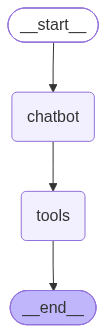

In [ ]:
# ============================================================================
# PART 4: Show Chatbot Graph
# ============================================================================

print("\n" + "="*80)
print("PART 4: Showing Chatbot Graph")
print("="*80)

display(Image(graph.get_graph().draw_mermaid_png()))



In [ ]:
# ============================================================================
# PART 5: Invoking Chatbot Graph
# ============================================================================

print("\n" + "="*80)
print("PART 5: Invoking Chatbot Graph")
print("="*80)

response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="Add 15 and 20. Then multiply the result by 5."
            )
        ]
    }
)

print(f"✓ Invoked Chatbot Graph")



PART 5: Invoking Chatbot Graph
✓ Invoked Chatbot Graph


In [ ]:
# ============================================================================
# PART 5: Display the Agent's Response
# ============================================================================
print("\n" + "="*80)
print("PART 5: Displaying the Agent's Response")
print("="*80)

for message in response["messages"]:
    print(message.content)

print("\n" + "="*80)




PART 5: Displaying the Agent's Response
Add 15 and 20. Then multiply the result by 5.

35
175

